# 16. Comparación estadística de metaheurísticas

Una metaheurística es un algoritmo estocástico, así que dos corridas sobre la misma instancia, con semillas distintas, pueden terminar en soluciones de calidad distinta. El resultado de una sola corrida es, por tanto, una observación de una variable aleatoria, y afirmar que un método es mejor que otro a partir de una corrida de cada uno equivale a comparar dos muestras de tamaño uno. Para comparar metaheurísticas con fundamento hay que repetir las corridas, resumir las distribuciones que resultan y usar pruebas estadísticas que digan si las diferencias observadas superan lo que cabría esperar por azar. Este capítulo recorre ese procedimiento con cuatro metaheurísticas aplicadas al problema del agente viajero (TSP, *traveling salesman problem*): un algoritmo genético, una optimización por enjambre de partículas, GRASP y una búsqueda de vecindario variable. Se generan varias instancias, cada algoritmo se ejecuta varias veces en cada una y los resultados se analizan con estadística descriptiva, pruebas de supuestos, pruebas para dos algoritmos y pruebas para varios algoritmos, con sus tamaños de efecto y un diagrama de diferencias críticas.

## Bibliotecas

Además de las bibliotecas usuales, el capítulo usa `scipy.stats` para las pruebas clásicas, `scikit-posthocs` para las pruebas *post hoc* y el diagrama de diferencias críticas, `pingouin` para los tamaños de efecto y DEAP para el algoritmo genético. En Colab hace falta instalar algunas de ellas, y para eso basta descomentar la línea de la celda siguiente.

In [1]:
# Instalación de bibliotecas (descomentar en Colab si no están instaladas)
# !pip install numpy pandas scipy matplotlib seaborn deap scikit-posthocs pingouin

In [2]:
import math
import random
import time
import itertools
import zlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas de estadística
import scipy.stats as stats
import scikit_posthocs as sp
import pingouin as pg # Para tamaños del efecto y CIs más fácilmente

# Para Algoritmos Genéticos con DEAP
from deap import base, creator, tools, algorithms

# Configuraciones generales para gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Bibliotecas importadas y configuración lista.")

Bibliotecas importadas y configuración lista.


## El problema y sus instancias

Una instancia del TSP es un conjunto de ciudades con coordenadas en el plano. Una solución es una permutación de las ciudades, y su costo es la longitud del recorrido cerrado que las visita en ese orden y regresa a la primera. Las funciones siguientes generan ciudades aleatorias en un cuadrado de 100 por 100, calculan la matriz de distancias euclidianas y evalúan la longitud de un recorrido.

In [3]:
def generate_cities(num_cities, width=100, height=100, seed=None):
    """Genera `num_cities` con coordenadas (x, y) aleatorias."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed) # Numpy también usa su propia semilla
    cities = []
    for _ in range(num_cities):
        cities.append((random.uniform(0, width), random.uniform(0, height)))
    return np.array(cities)

def calculate_distance_matrix(cities):
    """Calcula la matriz de distancias euclidianas entre todas las pares de ciudades."""
    num_cities = len(cities)
    distance_matrix = np.zeros((num_cities, num_cities))
    for i in range(num_cities):
        for j in range(i + 1, num_cities):
            dist = np.linalg.norm(cities[i] - cities[j])
            distance_matrix[i][j] = dist
            distance_matrix[j][i] = dist
    return distance_matrix

def calculate_tour_length(tour, distance_matrix):
    """Calcula la longitud total de un recorrido (tour) dado."""
    total_distance = 0
    num_cities = len(tour)
    if num_cities == 0: # Manejar tour vacío
        return float('inf')
    for i in range(num_cities):
        from_city = tour[i]
        to_city = tour[(i + 1) % num_cities] # Regresa a la ciudad de origen
        total_distance += distance_matrix[from_city, to_city]
    return total_distance

## Las cuatro metaheurísticas

Las cuatro implementaciones son versiones simplificadas, pensadas para que el experimento corra en poco tiempo y no para competir con los mejores métodos para el TSP. Todas reciben la matriz de distancias y una semilla, y devuelven la longitud del mejor recorrido encontrado y el recorrido.

### Algoritmo genético

Es el mismo esquema del capítulo 15, construido con DEAP, y es la base de los algoritmos meméticos del capítulo 13. Cada individuo es una permutación de las ciudades. El cruce ordenado (`cxOrdered`) produce hijos que siguen siendo permutaciones, la mutación baraja posiciones con probabilidad 0,05 por posición (`mutShuffleIndexes`) y la selección es por torneo de tamaño 3. El algoritmo `eaSimple` aplica cruce con probabilidad `cxpb` y mutación con probabilidad `mutpb` a cada individuo, y un salón de la fama (`HallOfFame`) guarda el mejor individuo visto.

In [4]:
# --- 3.1 Algoritmo Genético (GA) con DEAP ---
def run_genetic_algorithm_tsp(distance_matrix, n_gen=100, pop_size=50, cxpb=0.7, mutpb=0.2, seed=None):
    """Ejecuta un Algoritmo Genético para el TSP usando DEAP."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    num_cities = distance_matrix.shape[0]

    # Verificar si los tipos ya están registrados para evitar errores en re-ejecuciones de celda
    if not hasattr(creator, "FitnessMin"):
        creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
    if not hasattr(creator, "Individual"):
        creator.create("Individual", list, fitness=creator.FitnessMin)


    toolbox = base.Toolbox()
    toolbox.register("indices", random.sample, range(num_cities), num_cities)
    toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.indices)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)

    def evalTSP(individual):
        return calculate_tour_length(individual, distance_matrix),

    toolbox.register("evaluate", evalTSP)
    toolbox.register("mate", tools.cxOrdered)
    toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.05) # Prob de mutar cada gen
    toolbox.register("select", tools.selTournament, tournsize=3)

    pop = toolbox.population(n=pop_size)
    hof = tools.HallOfFame(1) # Guardar el mejor individuo

    stats_fit = tools.Statistics(lambda ind: ind.fitness.values)
    stats_fit.register("min", np.min)

    # Ejecutar el algoritmo genético
    algorithms.eaSimple(pop, toolbox, cxpb, mutpb, n_gen, stats=stats_fit, halloffame=hof, verbose=False)

    if hof: # Asegurarse que HallOfFame no esté vacío
        return hof[0].fitness.values[0], hof[0]
    else: # Si no se encontró ninguna solución (muy improbable con eaSimple si pop_size > 0)
        return float('inf'), []

### Optimización por enjambre de partículas

El PSO del capítulo 11 trabaja en un espacio continuo. Para usarlo en el TSP, cada partícula es un vector de $n$ números en $[0,1]$ y se decodifica con la regla del menor valor de posición (SPV, *smallest position value*), que ordena las ciudades de menor a mayor según su componente del vector, de modo que la permutación es `argsort(x)`. La velocidad y la posición se actualizan con la regla de siempre,

$$
v_i \leftarrow w\, v_i + c_1 r_1 \,(p_i - x_i) + c_2 r_2\, (g - x_i), \qquad x_i \leftarrow \min\{\max\{x_i + v_i,\, 0\},\, 1\},
$$

donde $p_i$ es la mejor posición de la partícula, $g$ la mejor del enjambre y $r_1, r_2 \sim U(0,1)$ se sortean una vez por partícula y por iteración. La posición se recorta al intervalo $[0,1]$.

In [5]:
# --- 3.2 Particle Swarm Optimization (PSO) para TSP (Adaptación muy simplificada) ---
# PSO es para espacios continuos. Para TSP (discreto), se necesita una decodificación.
# Usaremos una regla simple: Smallest Position Value (SPV)
def spv_decode(particle_position):
    """Decodifica la posición de una partícula a una permutación usando SPV."""
    return list(np.argsort(particle_position))

def run_pso_tsp(distance_matrix, n_particles=30, n_iterations=100, w=0.5, c1=1.5, c2=1.5, seed=None):
    """Ejecuta una versión muy simplificada de PSO para TSP."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    num_cities = distance_matrix.shape[0]
    if num_cities == 0: return float('inf'), []

    # Inicializar partículas: posiciones y velocidades aleatorias
    particles_position = np.random.rand(n_particles, num_cities)
    particles_velocity = np.random.rand(n_particles, num_cities) * 0.1 # Velocidades pequeñas

    # Mejores posiciones personales y sus fitness
    pbest_positions = np.copy(particles_position)
    pbest_fitness = np.array([float('inf')] * n_particles)

    # Mejor posición global y su fitness
    gbest_position = np.random.rand(num_cities)
    gbest_fitness = float('inf')

    # Inicializar pbest y gbest
    for i in range(n_particles):
        tour = spv_decode(particles_position[i])
        if not tour: continue
        fitness = calculate_tour_length(tour, distance_matrix)
        pbest_fitness[i] = fitness
        pbest_positions[i] = np.copy(particles_position[i]) # Guardar la posición que dio ese fitness
        if fitness < gbest_fitness:
            gbest_fitness = fitness
            gbest_position = np.copy(particles_position[i])

    if np.isinf(gbest_fitness) and n_particles > 0 :
        gbest_position = np.copy(particles_position[0]) # Asegurar inicialización


    for iteration in range(n_iterations):
        for i in range(n_particles):
            # Actualizar velocidad
            r1, r2 = random.random(), random.random()
            cognitive_velocity = c1 * r1 * (pbest_positions[i] - particles_position[i])
            social_velocity = c2 * r2 * (gbest_position - particles_position[i])
            particles_velocity[i] = w * particles_velocity[i] + cognitive_velocity + social_velocity

            # Actualizar posición
            particles_position[i] += particles_velocity[i]
            particles_position[i] = np.clip(particles_position[i], 0, 1) # Mantener en [0,1]

            # Evaluar nueva posición
            current_tour = spv_decode(particles_position[i])
            if not current_tour: continue
            current_fitness = calculate_tour_length(current_tour, distance_matrix)

            if current_fitness < pbest_fitness[i]:
                pbest_fitness[i] = current_fitness
                pbest_positions[i] = np.copy(particles_position[i])

                if current_fitness < gbest_fitness:
                    gbest_fitness = current_fitness
                    gbest_position = np.copy(particles_position[i])

    if np.isinf(gbest_fitness):
        return float('inf'), []

    best_tour_decoded = spv_decode(gbest_position)
    return gbest_fitness, best_tour_decoded

### GRASP

GRASP (*greedy randomized adaptive search procedure*) repite dos fases. La construcción parte de una ciudad al azar y, en cada paso, arma una lista restringida de candidatos (RCL, *restricted candidate list*) con las ciudades no visitadas cuya distancia a la última ciudad del recorrido no supera el umbral

$$
c_{\min} + \alpha\,(c_{\max} - c_{\min}),
$$

donde $c_{\min}$ y $c_{\max}$ son la menor y la mayor distancia entre los candidatos; la siguiente ciudad se elige al azar dentro de la RCL. Con $\alpha = 0$ la construcción es voraz y con $\alpha = 1$ es aleatoria. La segunda fase mejora el recorrido construido con una búsqueda local 2-opt de primera mejora, que invierte el segmento entre dos posiciones y acepta el primer cambio que acorta el recorrido. GRASP devuelve el mejor recorrido de todas las iteraciones.

In [6]:
# --- 3.3 GRASP (Greedy Randomized Adaptive Search Procedure) para TSP (Simplificado) ---
def grasp_construction(distance_matrix, rcl_alpha=0.3, seed=None):
    """Fase de construcción de GRASP."""
    if seed is not None:
        random.seed(seed)
    num_cities = distance_matrix.shape[0]
    if num_cities == 0: return []

    start_node = random.randint(0, num_cities - 1)
    current_tour = [start_node]
    unvisited = list(range(num_cities))
    unvisited.remove(start_node)

    while unvisited:
        last_city_in_tour = current_tour[-1]
        candidates = []
        for city_idx in unvisited:
            candidates.append((distance_matrix[last_city_in_tour, city_idx], city_idx))

        if not candidates: break
        candidates.sort()

        min_cost = candidates[0][0]
        max_cost = candidates[-1][0]

        if min_cost == max_cost :
             threshold = min_cost
        else:
            threshold = min_cost + rcl_alpha * (max_cost - min_cost)

        rcl = [city_idx for cost, city_idx in candidates if cost <= threshold + 1e-9] # Tolerancia para flotantes

        if not rcl:
            chosen_city = candidates[0][1]
        else:
            chosen_city = random.choice(rcl)

        current_tour.append(chosen_city)
        unvisited.remove(chosen_city)

    return current_tour

def local_search_2opt(tour, distance_matrix):
    """Búsqueda local 2-opt simple."""
    if not tour or len(tour) < 2: return calculate_tour_length(tour, distance_matrix) if tour else float('inf'), list(tour)

    best_tour = list(tour)
    best_length = calculate_tour_length(best_tour, distance_matrix)
    num_cities = len(best_tour)

    improved = True

    while improved:
        improved = False
        for i in range(num_cities - 1):
            for j in range(i + 1, num_cities):
                if num_cities <= 2 : continue # No hay segmento para invertir si solo hay 2 ciudades en el tour
                # El segmento a invertir es tour[i+1]...tour[j]
                # No invertir si j es el último y i es el antepenúltimo (equivaldría a invertir solo el último arco con el primero)
                # o si el segmento es demasiado corto.
                # Para 2-opt, el segmento debe tener al menos 2 ciudades para que la inversión tenga sentido
                # (i.e., j > i+1)
                if j <= i + 1 and num_cities > 3 : continue # El segmento entre i+1 y j debe tener al menos 1 ciudad para invertir.
                                                 # Si j=i+1, el segmento es vacío o de 1.
                                                 # Si num_cities=3, i=0, j=1, segmento es tour[1]. No tiene sentido.
                                                 # Si num_cities=3, i=0, j=2, segmento es tour[1], tour[2]. Sí tiene sentido.

                new_tour = best_tour[:]
                segment_to_reverse = new_tour[i+1 : j+1]
                segment_to_reverse.reverse()
                new_tour[i+1 : j+1] = segment_to_reverse

                new_length = calculate_tour_length(new_tour, distance_matrix)

                if new_length < best_length - 1e-9: # Usar tolerancia para flotantes
                    best_tour = new_tour[:]
                    best_length = new_length
                    improved = True
                    break
            if improved:
                break
    return best_length, best_tour


def run_grasp_tsp(distance_matrix, n_grasp_iterations=50, rcl_alpha=0.3, seed=None):
    """Ejecuta GRASP para TSP."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    best_overall_fitness = float('inf')
    best_overall_tour = None

    for iter_num in range(n_grasp_iterations):
        construction_seed = seed + iter_num if seed is not None else None
        constructed_tour = grasp_construction(distance_matrix, rcl_alpha, seed=construction_seed)
        if not constructed_tour : continue

        fitness, improved_tour = local_search_2opt(constructed_tour, distance_matrix)

        if fitness < best_overall_fitness:
            best_overall_fitness = fitness
            best_overall_tour = improved_tour[:]

    return best_overall_fitness, best_overall_tour

### Búsqueda de vecindario variable

La búsqueda de vecindario variable (VNS, *variable neighborhood search*) parte de un recorrido aleatorio mejorado con 2-opt y alterna dos vecindarios para sacudir (*shake*) la solución actual; el primero intercambia dos ciudades y el segundo invierte un segmento. Después de cada sacudida se aplica la búsqueda local 2-opt. Si el resultado mejora la solución actual, se acepta y se vuelve al primer vecindario; si no, se pasa al siguiente. El algoritmo se detiene al llegar al número máximo de iteraciones o cuando el número de iteraciones seguidas sin mejora supera un tercio de ese máximo.

In [7]:
# --- 3.4 Variable Neighborhood Search (VNS) para TSP (Simplificado) ---
def vns_shake(tour, k_neighborhood, seed=None):
    """Genera una solución aleatoria en el k-ésimo vecindario."""
    if not tour : return []
    if seed is not None:
        random.seed(seed)

    shaken_tour = list(tour)
    num_cities = len(shaken_tour)
    if num_cities < 2 : return shaken_tour

    if k_neighborhood == 1: # Vecindario de intercambio (swap)
        if num_cities < 2: return shaken_tour
        idx1, idx2 = random.sample(range(num_cities), 2)
        shaken_tour[idx1], shaken_tour[idx2] = shaken_tour[idx2], shaken_tour[idx1]

    elif k_neighborhood == 2: # Vecindario de inversión de segmento (similar a 2-opt move)
        if num_cities < 3: return shaken_tour

        idx1, idx2 = sorted(random.sample(range(num_cities), 2))
        if idx1 == idx2 : # Asegurar que sean distintos para tener un segmento
             idx2 = (idx1 + 1) % num_cities
             if idx2 == idx1 and num_cities > 1: # Si solo hay una ciudad, no hacer nada
                  idx2 = (idx1 + random.randint(1, num_cities -1)) % num_cities
             elif num_cities == 1:
                  return shaken_tour
             idx1, idx2 = sorted([idx1, idx2])


        segment = shaken_tour[idx1 : idx2+1]
        segment.reverse()
        shaken_tour = shaken_tour[:idx1] + segment + shaken_tour[idx2+1:]
    return shaken_tour

def run_vns_tsp(distance_matrix, max_iterations=100, k_max=2, seed=None):
    """Ejecuta VNS para TSP."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    num_cities = distance_matrix.shape[0]
    if num_cities == 0: return float('inf'), []

    current_tour = list(range(num_cities))
    random.shuffle(current_tour)
    current_fitness, current_tour = local_search_2opt(current_tour, distance_matrix) # Mejorar solución inicial

    best_tour_overall = current_tour[:]
    best_fitness_overall = current_fitness

    iteration = 0
    no_improvement_streak = 0
    max_no_improvement = max_iterations // 3

    while iteration < max_iterations:
        k = 1
        improvement_in_iteration_vns = False
        while k <= k_max:
            shake_seed = seed + iteration * k_max + k if seed is not None else None
            shaken_tour = vns_shake(list(current_tour), k, seed=shake_seed)
            if not shaken_tour:
                k += 1
                continue

            improved_fitness, improved_tour_after_ls = local_search_2opt(shaken_tour, distance_matrix)

            if improved_fitness < current_fitness - 1e-9: # Usar tolerancia
                current_tour = improved_tour_after_ls[:]
                current_fitness = improved_fitness
                improvement_in_iteration_vns = True
                if current_fitness < best_fitness_overall - 1e-9:
                    best_fitness_overall = current_fitness
                    best_tour_overall = current_tour[:]
                k = 1
            else:
                k += 1

        if not improvement_in_iteration_vns:
            no_improvement_streak += 1
        else:
            no_improvement_streak = 0

        if no_improvement_streak > max_no_improvement and max_no_improvement > 0:
            break
        iteration += 1

    return best_fitness_overall, best_tour_overall

print("Implementaciones de metaheurísticas listas (simplificadas).")

Implementaciones de metaheurísticas listas (simplificadas).


## Diseño experimental

El experimento cruza tres factores: la instancia, el algoritmo y la corrida. Se generan cinco instancias, cada una con 10 o 15 ciudades elegidas al azar, y cada algoritmo se ejecuta siete veces en cada instancia, con una semilla distinta en cada corrida. El número de corridas es pequeño para que el cuaderno corra rápido; en un estudio real se suelen hacer entre 10 y 30 corridas independientes, o más, por algoritmo e instancia. Los parámetros de cada algoritmo también son pequeños, de modo que cada corrida dure poco.

La semilla de cada corrida se deriva del nombre de la instancia, del algoritmo y del número de corrida. Así, cada corrida es reproducible y distinta de las demás. Para que la derivación dé el mismo número en cualquier sesión de Python se usa la suma de verificación CRC32 del texto.

Este diseño permite dos tipos de comparación. Dentro de una instancia, las siete corridas de cada algoritmo son muestras independientes. A través de las instancias, cada instancia funciona como un bloque, y cada algoritmo aporta un valor resumen por instancia (la mediana de sus corridas), de modo que los valores de los distintos algoritmos quedan pareados por instancia.

In [8]:
random.seed(42)
np.random.seed(42)

# --- Parámetros del Experimento ---
N_INSTANCES = 5
N_CITIES_PER_INSTANCE = [10, 15] # Reducido para ejecución más rápida
N_EXECUTIONS_PER_ALGO_INSTANCE = 7 # Número impar para medianas claras, >5 para algunas pruebas

ALGORITHMS = {
    "GA": run_genetic_algorithm_tsp,
    "PSO": run_pso_tsp,
    "GRASP": run_grasp_tsp,
    "VNS": run_vns_tsp
}
ALGORITHM_NAMES = list(ALGORITHMS.keys())


# --- Generar Instancias TSP ---
tsp_instances = []
instance_names = []
print("Generando instancias TSP...")
for i in range(N_INSTANCES):
    num_cities = random.choice(N_CITIES_PER_INSTANCE)
    instance_name = f"TSP_{num_cities}c_inst{i+1}"
    cities = generate_cities(num_cities, seed=42 + i)
    dist_matrix = calculate_distance_matrix(cities)
    tsp_instances.append({"name": instance_name, "matrix": dist_matrix, "num_cities": num_cities})
    instance_names.append(instance_name)
    print(f"  Generada instancia: {instance_name} con {num_cities} ciudades.")

Generando instancias TSP...
  Generada instancia: TSP_10c_inst1 con 10 ciudades.
  Generada instancia: TSP_10c_inst2 con 10 ciudades.
  Generada instancia: TSP_15c_inst3 con 15 ciudades.
  Generada instancia: TSP_10c_inst4 con 10 ciudades.
  Generada instancia: TSP_10c_inst5 con 10 ciudades.


In [9]:
# --- Recolección de Resultados ---
results_list = []
start_time_experiment = time.time()
print("\nIniciando recolección de resultados experimentales...")

for instance_data in tsp_instances:
    instance_name = instance_data["name"]
    dist_matrix = instance_data["matrix"]
    num_cities_current = instance_data["num_cities"]
    print(f"\nProcesando instancia: {instance_name} ({num_cities_current} ciudades)")

    for algo_name, algo_func in ALGORITHMS.items():
        print(f"  Ejecutando {algo_name}...")
        for exec_id in range(N_EXECUTIONS_PER_ALGO_INSTANCE):
            base_seed_str = f"{instance_name}_{algo_name}_{exec_id}"
            # Semilla determinista (hash() de Python cambia entre sesiones)
            exec_seed = int(zlib.crc32(base_seed_str.encode()) % (2**31 -1))

            fitness = float('nan')
            tour = []

            try:
                # Parámetros para ejecución rápida de demo
                if algo_name == "GA":
                    fitness, tour = algo_func(dist_matrix, n_gen=25, pop_size=15, cxpb=0.8, mutpb=0.15, seed=exec_seed)
                elif algo_name == "PSO":
                    fitness, tour = algo_func(dist_matrix, n_particles=10, n_iterations=25, w=0.6, c1=1.2, c2=1.2, seed=exec_seed)
                elif algo_name == "GRASP":
                    fitness, tour = algo_func(dist_matrix, n_grasp_iterations=15, rcl_alpha=0.3, seed=exec_seed)
                elif algo_name == "VNS":
                    fitness, tour = algo_func(dist_matrix, max_iterations=25, k_max=2, seed=exec_seed)

                results_list.append({
                    "instance": instance_name,
                    "num_cities": num_cities_current,
                    "algorithm": algo_name,
                    "execution": exec_id + 1,
                    "seed_used": exec_seed,
                    "fitness": fitness
                })
            except Exception as e:
                print(f"    ERROR en {algo_name} ejecución {exec_id+1} para {instance_name}: {e}")
                results_list.append({
                    "instance": instance_name,
                    "num_cities": num_cities_current,
                    "algorithm": algo_name,
                    "execution": exec_id + 1,
                    "seed_used": exec_seed,
                    "fitness": float('inf')
                })


results_df = pd.DataFrame(results_list)
end_time_experiment = time.time()
print(f"\n--- Experimento completado en {end_time_experiment - start_time_experiment:.2f} segundos ---")

if not results_df.empty:
    print("\nPrimeras filas de los resultados:")
    print(results_df.head())
    print(f"\nTotal de resultados recolectados: {len(results_df)}")
else:
    print("No se generaron resultados. Verifica el bucle de recolección.")


Iniciando recolección de resultados experimentales...

Procesando instancia: TSP_10c_inst1 (10 ciudades)
  Ejecutando GA...
  Ejecutando PSO...
  Ejecutando GRASP...
  Ejecutando VNS...

Procesando instancia: TSP_10c_inst2 (10 ciudades)
  Ejecutando GA...
  Ejecutando PSO...
  Ejecutando GRASP...
  Ejecutando VNS...

Procesando instancia: TSP_15c_inst3 (15 ciudades)
  Ejecutando GA...


  Ejecutando PSO...


  Ejecutando GRASP...


  Ejecutando VNS...

Procesando instancia: TSP_10c_inst4 (10 ciudades)
  Ejecutando GA...


  Ejecutando PSO...


  Ejecutando GRASP...
  Ejecutando VNS...

Procesando instancia: TSP_10c_inst5 (10 ciudades)
  Ejecutando GA...


  Ejecutando PSO...
  Ejecutando GRASP...
  Ejecutando VNS...

--- Experimento completado en 0.59 segundos ---

Primeras filas de los resultados:
        instance  num_cities algorithm  execution   seed_used     fitness
0  TSP_10c_inst1          10        GA          1  1826475668  295.702973
1  TSP_10c_inst1          10        GA          2   467336710  365.655767
2  TSP_10c_inst1          10        GA          3    47427519  326.508312
3  TSP_10c_inst1          10        GA          4  1976868649  303.052954
4  TSP_10c_inst1          10        GA          5  1806699147  273.763550

Total de resultados recolectados: 140


## Análisis descriptivo

Antes de cualquier prueba hay que mirar los datos. Las tablas resumen la longitud del recorrido (la medida de desempeño, que se minimiza) por algoritmo y por algoritmo e instancia, y los diagramas de caja muestran su distribución. El primer diagrama mezcla todas las instancias, de modo que su dispersión incluye la diferencia de tamaño entre instancias de 10 y de 15 ciudades; el segundo separa las instancias y es el que permite comparar los algoritmos en igualdad de condiciones. El histograma final muestra la distribución de las siete corridas de un algoritmo en una instancia.

In [10]:
print("\n--- 5. Análisis Estadístico Descriptivo ---")

if not results_df.empty:
    print("\nEstadísticas descriptivas generales del fitness:")
    print(results_df['fitness'].describe())

    print("\nEstadísticas descriptivas del fitness por algoritmo (agrupando todas las instancias):")
    print(results_df.groupby('algorithm')['fitness'].describe())

    if N_INSTANCES <= 10:
        print("\nEstadísticas descriptivas del fitness por algoritmo e instancia:")
        print(results_df.groupby(['instance', 'algorithm'])['fitness'].agg(['mean', 'median', 'std', 'min', 'max']))


--- 5. Análisis Estadístico Descriptivo ---

Estadísticas descriptivas generales del fitness:
count    140.000000
mean     365.976383
std       99.000694
min      264.023388
25%      297.110971
50%      356.226263
75%      409.891288
max      703.575977
Name: fitness, dtype: float64

Estadísticas descriptivas del fitness por algoritmo (agrupando todas las instancias):
           count        mean         std         min         25%         50%  \
algorithm                                                                      
GA          35.0  394.109663  105.007136  264.023388  321.215514  367.141950   
GRASP       35.0  320.071631   57.920658  264.023388  264.138876  301.897017   
PSO         35.0  429.352768  114.299697  293.462018  344.400400  389.731051   
VNS         35.0  320.371472   57.999745  264.023388  264.138876  301.897017   

                  75%         max  
algorithm                          
GA         449.500007  635.016552  
GRASP      360.407589  409.891288  
PSO

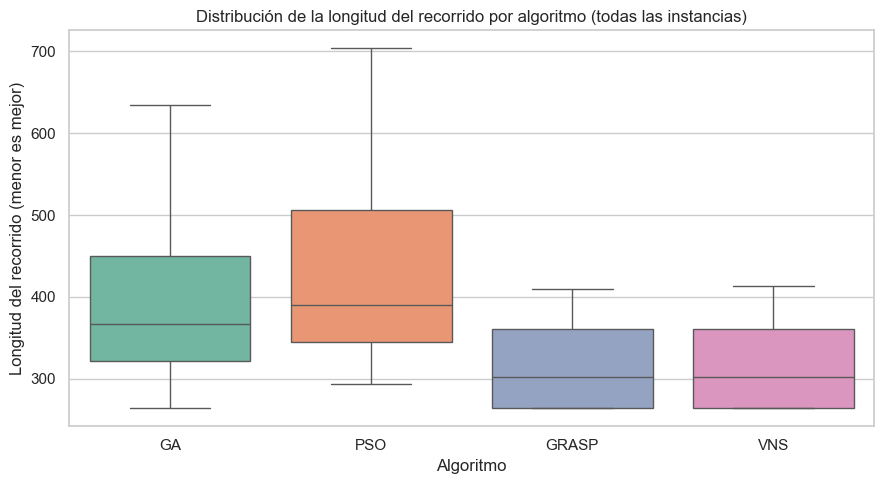

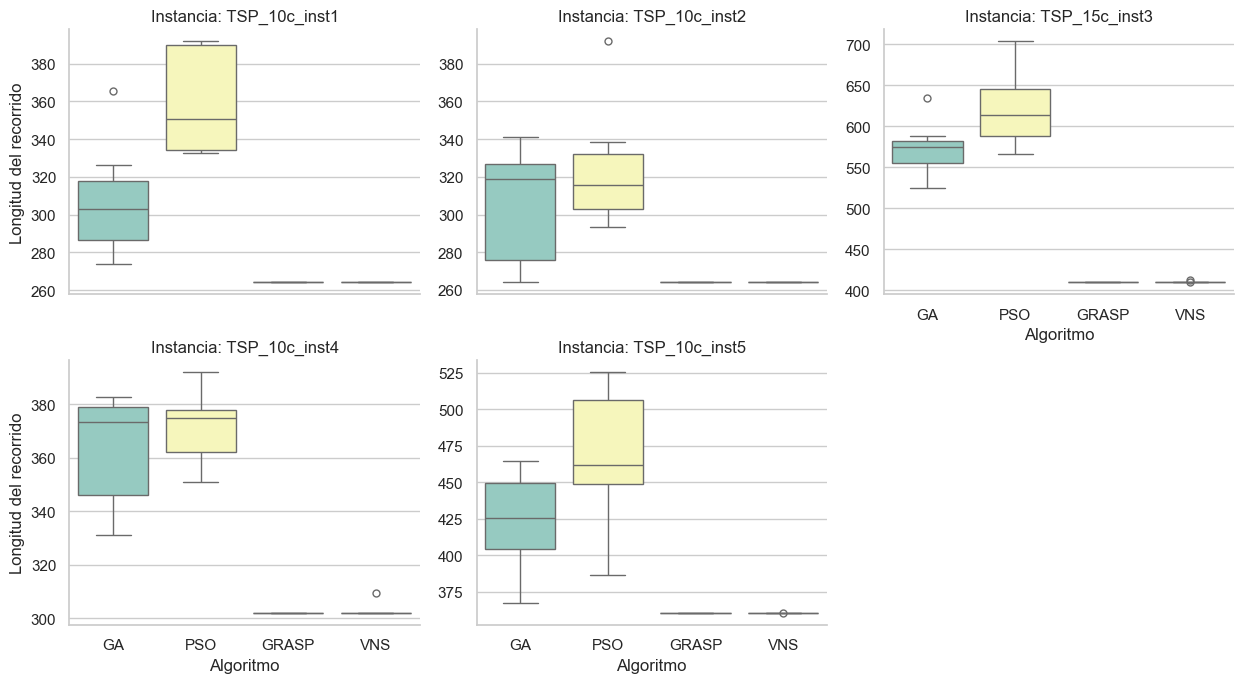

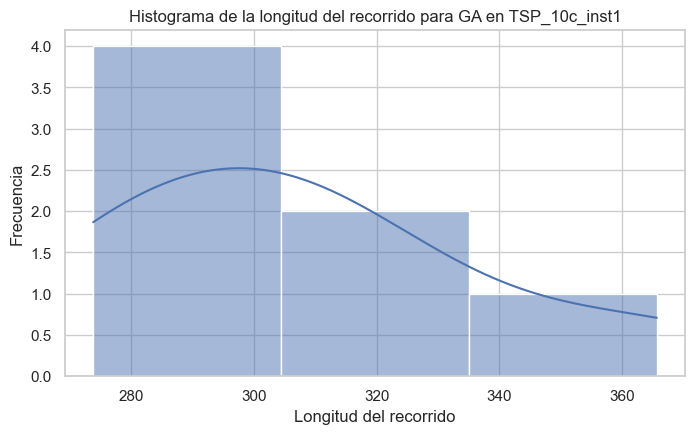

In [11]:
if not results_df.empty:
    plt.figure(figsize=(9, 5))
    sns.boxplot(x='algorithm', y='fitness', data=results_df, hue='algorithm', legend=False,
                palette="Set2", order=ALGORITHM_NAMES)
    plt.title('Distribución de la longitud del recorrido por algoritmo (todas las instancias)')
    plt.ylabel('Longitud del recorrido (menor es mejor)')
    plt.xlabel('Algoritmo')
    plt.tight_layout()
    plt.show()

    if results_df['instance'].nunique() > 1:
        g = sns.catplot(x='algorithm', y='fitness', col='instance', data=results_df,
                        kind='box', col_wrap=min(3, results_df['instance'].nunique()),
                        height=3.5, aspect=1.2, hue='algorithm', legend=False,
                        palette="Set3", order=ALGORITHM_NAMES,
                        sharey=False)
        g.set_titles("Instancia: {col_name}")
        g.set_axis_labels("Algoritmo", "Longitud del recorrido")
        plt.tight_layout()
        plt.show()

    if N_EXECUTIONS_PER_ALGO_INSTANCE > 1 and results_df['instance'].nunique() > 0 and len(ALGORITHM_NAMES) > 0:
        example_instance_for_hist = results_df['instance'].unique()[0]
        example_algo_for_hist = ALGORITHM_NAMES[0]

        data_for_hist = results_df[
            (results_df['instance'] == example_instance_for_hist) &
            (results_df['algorithm'] == example_algo_for_hist)
        ]['fitness'].dropna()

        if not data_for_hist.empty and len(data_for_hist) > 1:
            plt.figure(figsize=(8, 4.5))
            sns.histplot(data_for_hist, kde=True, bins=max(3, N_EXECUTIONS_PER_ALGO_INSTANCE // 2))
            plt.title(f'Histograma de la longitud del recorrido para {example_algo_for_hist} en {example_instance_for_hist}')
            plt.xlabel('Longitud del recorrido')
            plt.ylabel('Frecuencia')
            plt.show()
        else:
            print(f"No hay suficientes datos para el histograma de {example_algo_for_hist} en {example_instance_for_hist}")
else:
    print("DataFrame de resultados vacío, no se pueden generar gráficos descriptivos.")

Las tablas y los diagramas por instancia muestran dos grupos de algoritmos. GRASP y VNS terminan en todas sus corridas en el mismo valor, o casi, y coinciden entre sí en cada instancia, de modo que su dispersión es nula o muy pequeña. El algoritmo genético y el PSO producen recorridos más largos y mucho más variables de una corrida a otra, y en las cinco instancias la media del PSO es la mayor de los cuatro. El diagrama que mezcla todas las instancias exagera la dispersión de todos los algoritmos, porque junta recorridos de instancias de 10 y de 15 ciudades; por eso las pruebas que siguen comparan dentro de una instancia o usan la instancia como bloque.

## Supuestos de las pruebas paramétricas

Las pruebas paramétricas para comparar medias, como la prueba $t$ o el análisis de varianza (ANOVA), suponen que los datos de cada grupo siguen una distribución normal y que los grupos tienen la misma varianza (homocedasticidad). Con resultados de metaheurísticas estos supuestos fallan a menudo, porque las distribuciones suelen ser asimétricas, quedar acotadas por el valor óptimo o concentrarse en unos pocos valores cuando el algoritmo encuentra varias veces la misma solución. Por eso, antes de elegir la prueba, se verifican los supuestos.

La prueba de Shapiro-Wilk tiene como hipótesis nula que los datos provienen de una distribución normal, y la de Levene, que todos los grupos tienen la misma varianza. En ambas, un valor $p$ menor o igual que el nivel de significancia $\alpha = 0{,}05$ lleva a rechazar la hipótesis nula. Un valor $p$ mayor no prueba que el supuesto se cumpla; solo indica que los datos no dan evidencia suficiente en su contra, y con siete observaciones por grupo esa evidencia es escasa. El código analiza la primera instancia.

In [12]:
print("\n--- 6. Pruebas de Supuestos Estadísticos ---")
alpha_supuestos = 0.05

if not results_df.empty and results_df['instance'].nunique() > 0:
    target_instance_name_supuestos = results_df['instance'].unique()[0]
    print(f"\nAnálisis de supuestos para la instancia: {target_instance_name_supuestos}")


    for algo_name in ALGORITHM_NAMES:
        data_algo_instance = results_df[
            (results_df['instance'] == target_instance_name_supuestos) &
            (results_df['algorithm'] == algo_name)
        ]['fitness'].dropna()

        if len(data_algo_instance) >= 3 and data_algo_instance.nunique() == 1:
            # Con datos constantes (todas las corridas iguales) la prueba no aplica
            print(f"  Normalidad (Shapiro-Wilk) para {algo_name}: No aplica (datos constantes)")
        elif len(data_algo_instance) >= 3:
            stat_shapiro, p_shapiro = stats.shapiro(data_algo_instance)
            is_normal = p_shapiro > alpha_supuestos
            print(f"  Normalidad (Shapiro-Wilk) para {algo_name}: p-valor = {p_shapiro:.4f} "
                  f"-> {'Normal' if is_normal else 'No Normal'}")
        else:
            print(f"  No hay suficientes datos para prueba de normalidad en {algo_name} para {target_instance_name_supuestos} (muestras: {len(data_algo_instance)})")

    data_for_levene_check = []
    groups_with_enough_data_levene = 0
    for algo_name in ALGORITHM_NAMES:
        group_data = results_df[
            (results_df['instance'] == target_instance_name_supuestos) &
            (results_df['algorithm'] == algo_name)
        ]['fitness'].dropna()
        if len(group_data) > 1:
            data_for_levene_check.append(group_data)
            groups_with_enough_data_levene +=1

    variances_equal_for_anova = False
    if groups_with_enough_data_levene >= 2 and all(len(g) > 1 for g in data_for_levene_check):
        stat_levene, p_levene = stats.levene(*data_for_levene_check)
        variances_equal_for_anova = p_levene > alpha_supuestos
        print(f"\n  Homocedasticidad (Levene) para {target_instance_name_supuestos} entre algoritmos: p-valor = {p_levene:.4f} "
              f"-> {'Varianzas Iguales' if variances_equal_for_anova else 'Varianzas Diferentes'}")
    elif groups_with_enough_data_levene < 2 :
         print(f"\n  No hay suficientes grupos (>1) para la prueba de Levene en {target_instance_name_supuestos}.")
    else:
        print(f"\n  No hay suficientes datos en los grupos para la prueba de Levene en {target_instance_name_supuestos}.")
else:
    print("DataFrame de resultados vacío o sin instancias, no se pueden realizar pruebas de supuestos.")


--- 6. Pruebas de Supuestos Estadísticos ---

Análisis de supuestos para la instancia: TSP_10c_inst1
  Normalidad (Shapiro-Wilk) para GA: p-valor = 0.4878 -> Normal
  Normalidad (Shapiro-Wilk) para PSO: p-valor = 0.0175 -> No Normal
  Normalidad (Shapiro-Wilk) para GRASP: No aplica (datos constantes)
  Normalidad (Shapiro-Wilk) para VNS: No aplica (datos constantes)

  Homocedasticidad (Levene) para TSP_10c_inst1 entre algoritmos: p-valor = 0.0012 -> Varianzas Diferentes


En la primera instancia, la prueba de Shapiro-Wilk no rechaza la normalidad del algoritmo genético y la rechaza para el PSO. Para GRASP y VNS la prueba no se aplica, porque las siete corridas dieron exactamente la misma longitud. Con datos constantes SciPy devuelve un valor $p$ de 1 acompañado de una advertencia, de modo que el código revisa primero si los datos son constantes y, en ese caso, informa que la prueba no aplica. La prueba de Levene rechaza la igualdad de varianzas, como era de esperar si dos grupos no tienen variación y los otros dos sí. Como fallan los dos supuestos, el análisis sigue con pruebas no paramétricas. Si se cumplieran, la alternativa paramétrica para varios algoritmos sería un ANOVA seguido de la prueba de Tukey.

## Comparación de dos algoritmos

El primer caso compara el algoritmo genético con el PSO. Las pruebas no paramétricas que siguen trabajan con rangos y no suponen normalidad.

Dentro de una instancia, las corridas de los dos algoritmos son muestras independientes, y la prueba adecuada es la U de Mann-Whitney, cuya hipótesis nula es que las dos distribuciones son iguales (de forma más precisa, que una observación de un algoritmo tiene la misma probabilidad de ser mayor o menor que una del otro). Además del valor $p$, `pingouin` informa dos tamaños de efecto. El CLES (*common language effect size*) es la proporción de pares (corrida del primer algoritmo, corrida del segundo) en que la del primero es mayor, contando los empates como medio. La correlación biserial de rangos (RBC, *rank-biserial correlation*) va de $-1$ a $1$ y, sin empates, vale $2\,\text{CLES} - 1$. Como aquí se minimiza, un CLES cercano a 1 o una RBC cercana a 1 indican que el primer algoritmo produce recorridos más largos, es decir, peores.

A través de las instancias, los dos algoritmos quedan pareados por instancia, y se usa la prueba de rangos con signo de Wilcoxon sobre las medianas de cada instancia. Su hipótesis nula es que la mediana de las diferencias es cero. Hay que tener presente el tamaño de la muestra. Con solo cinco instancias, el menor valor $p$ bilateral que puede dar la prueba exacta de Wilcoxon es $2/2^5 = 0{,}0625$, así que nunca podrá rechazar la hipótesis nula al 5 %, por grandes que sean las diferencias. Para que esta prueba tenga potencia se necesitan más instancias.

In [13]:
print("\n--- 7. Comparación de Dos Algoritmos ---")
alpha_comparacion = 0.05

if not results_df.empty and len(ALGORITHM_NAMES) >= 2:
    algo1_name_comp = ALGORITHM_NAMES[0]
    algo2_name_comp = ALGORITHM_NAMES[1]
    print(f"Comparando {algo1_name_comp} vs {algo2_name_comp}")

    target_instance_comp = results_df['instance'].unique()[0]
    print(f"\n  Escenario 1: Muestras Independientes en la instancia '{target_instance_comp}'")

    data_algo1_inst = results_df[(results_df['instance'] == target_instance_comp) & (results_df['algorithm'] == algo1_name_comp)]['fitness'].dropna()
    data_algo2_inst = results_df[(results_df['instance'] == target_instance_comp) & (results_df['algorithm'] == algo2_name_comp)]['fitness'].dropna()

    if len(data_algo1_inst) >=3 and len(data_algo2_inst) >=3:
        stat_mw, p_mw = stats.mannwhitneyu(data_algo1_inst, data_algo2_inst, alternative='two-sided')
        print(f"    Prueba U de Mann-Whitney: p-valor = {p_mw:.4f}")
        if p_mw <= alpha_comparacion: print("      Diferencia significativa en las distribuciones.")
        else: print("      No hay diferencia significativa en las distribuciones.")

        mwu_results_pg = pg.mwu(data_algo1_inst, data_algo2_inst, alternative='two-sided')
        print("    Resultados de Pingouin para Mann-Whitney U:")
        print(mwu_results_pg[['U-val', 'p-val', 'RBC', 'CLES']])
    else:
        print(f"    No hay suficientes datos para comparar {algo1_name_comp} y {algo2_name_comp} en {target_instance_comp}.")

    if results_df['instance'].nunique() > 1:
        print(f"\n  Escenario 2: Muestras Pareadas a través de {results_df['instance'].nunique()} instancias")

        paired_data_median = results_df.groupby(['instance', 'algorithm'])['fitness'].median().unstack()

        if algo1_name_comp in paired_data_median.columns and algo2_name_comp in paired_data_median.columns:
            data_algo1_paired_med = paired_data_median[algo1_name_comp].dropna()
            data_algo2_paired_med = paired_data_median[algo2_name_comp].dropna()

            common_index_paired = data_algo1_paired_med.index.intersection(data_algo2_paired_med.index)
            if len(common_index_paired) >= 3: # Wilcoxon necesita al menos algunas observaciones pareadas
                data_algo1_aligned_med = data_algo1_paired_med.loc[common_index_paired]
                data_algo2_aligned_med = data_algo2_paired_med.loc[common_index_paired]

                # Asegurar que no todos los valores de diferencia sean cero
                diffs = data_algo1_aligned_med - data_algo2_aligned_med
                if not np.all(np.isclose(diffs,0)) and len(diffs) > 0: # Usar isclose para flotantes
                    try:
                        stat_wilcoxon, p_wilcoxon = stats.wilcoxon(data_algo1_aligned_med, data_algo2_aligned_med)
                        print(f"    Prueba de Wilcoxon (pareada sobre medianas por instancia): p-valor = {p_wilcoxon:.4f}")
                        if p_wilcoxon <= alpha_comparacion: print("      Diferencia significativa.")
                        else: print("      No hay diferencia significativa.")

                        wilcoxon_results_pg = pg.wilcoxon(data_algo1_aligned_med, data_algo2_aligned_med)
                        print("    Resultados de Pingouin para Wilcoxon:")
                        print(wilcoxon_results_pg[['W-val','p-val', 'RBC', 'CLES']])
                    except ValueError as e_wilc: # Puede ocurrir si todos los pares son iguales o n es muy pequeño
                        print(f"    Error en la prueba de Wilcoxon: {e_wilc}. Puede ser debido a diferencias idénticas o n pequeño.")
                        print("      No se puede concluir significancia.")

                elif len(diffs) == 0:
                    print("    No hay datos alineados para la prueba de Wilcoxon.")
                else: # Todas las diferencias son cero
                    print("    Prueba de Wilcoxon (pareada): Todas las diferencias son cero (o muy cercanas a cero).")
                    print("      No hay diferencia significativa.")


            else:
                print(f"    No hay suficientes instancias comunes ({len(common_index_paired)}) con datos para {algo1_name_comp} y {algo2_name_comp} para una prueba pareada.")
        else:
            print(f"    Columnas de algoritmos no encontradas en datos pivoteados para prueba pareada.")
    else:
        print("\n  No hay múltiples instancias para una prueba pareada.")
else:
    print("DataFrame de resultados vacío o con menos de dos algoritmos, no se pueden realizar comparaciones de dos grupos.")


--- 7. Comparación de Dos Algoritmos ---
Comparando GA vs PSO

  Escenario 1: Muestras Independientes en la instancia 'TSP_10c_inst1'
    Prueba U de Mann-Whitney: p-valor = 0.0070
      Diferencia significativa en las distribuciones.
    Resultados de Pingouin para Mann-Whitney U:
     U-val     p-val       RBC      CLES
MWU    4.0  0.006993 -0.836735  0.081633

  Escenario 2: Muestras Pareadas a través de 5 instancias
    Prueba de Wilcoxon (pareada sobre medianas por instancia): p-valor = 0.1875
      No hay diferencia significativa.
    Resultados de Pingouin para Wilcoxon:
          W-val   p-val       RBC  CLES
Wilcoxon    2.0  0.1875 -0.733333   0.4


En la primera instancia, la prueba de Mann-Whitney da $p = 0{,}0070$, por debajo de 0,05, así que hay evidencia de que el algoritmo genético y el PSO producen distribuciones distintas. Los tamaños de efecto dicen en qué dirección y cuánto. El CLES es 0,08, de modo que solo en cerca del 8 % de los pares de corridas el recorrido del algoritmo genético es más largo que el del PSO, y la RBC, de $-0{,}84$, confirma que el algoritmo genético obtiene recorridos más cortos con mucha regularidad.

A través de las cinco instancias, la mediana del algoritmo genético es menor que la del PSO en cuatro de ellas, y la RBC pareada vale $-0{,}73$. Aun así, la prueba de Wilcoxon da $p = 0{,}1875$ y no permite rechazar la hipótesis nula, lo que ilustra la advertencia anterior sobre la falta de potencia de la prueba con cinco instancias. En esta prueba el CLES que informa `pingouin` compara todas las medianas de un algoritmo con todas las del otro, sin respetar el pareo por instancia, y como las instancias tienen tamaños distintos no sirve para interpretar esta comparación. Un valor $p$ mayor que 0,05 no prueba que los algoritmos sean equivalentes; solo dice que estos datos no bastan para distinguirlos.

## Comparación de varios algoritmos

Cuando se comparan $k > 2$ algoritmos, hacer todas las pruebas por pares infla la probabilidad de declarar al menos una diferencia falsa. El procedimiento estándar tiene dos pasos. Primero, una prueba ómnibus dice si hay alguna diferencia entre los $k$ algoritmos. Solo si la hay, unas pruebas *post hoc* dicen qué pares difieren, con una corrección que controla el error de tipo I del conjunto de comparaciones.

Dentro de una instancia, con muestras independientes, la prueba ómnibus es la de Kruskal-Wallis, la versión por rangos del ANOVA de un factor, y la prueba *post hoc* es la de Dunn, con los valores $p$ ajustados por el método de Holm.

A través de las instancias, con las medianas pareadas por instancia, la prueba ómnibus es la de Friedman. En cada instancia se ordenan los $k$ algoritmos del mejor (rango 1) al peor (rango $k$) y la prueba compara los rangos promedio $\bar{R}_j$. Su estadístico, con $n$ instancias, es

$$
\chi^2_F = \frac{12\,n}{k(k+1)} \left[\sum_{j=1}^{k} \bar{R}_j^{\,2} - \frac{k(k+1)^2}{4}\right],
$$

y el código lo acompaña de su tamaño de efecto, la $W$ de Kendall,

$$
W = \frac{\chi^2_F}{n\,(k-1)},
$$

que va de 0, cuando los rangos no coinciden entre instancias, a 1, cuando todas las instancias ordenan los algoritmos igual. Si la prueba de Friedman resulta significativa, la prueba de Nemenyi compara todos los pares, y el diagrama de diferencias críticas (*critical difference diagram*) resume el resultado. Cada algoritmo aparece en un eje según su rango promedio, y una barra horizontal une los algoritmos cuyas diferencias no son significativas. Si la prueba no resulta significativa, el código muestra solo los rangos promedio.


--- 8. Comparación de Múltiples Algoritmos (K > 2) ---

  Escenario 1: Comparación en la instancia 'TSP_10c_inst1' (Usando Kruskal-Wallis)
    Test de Kruskal-Wallis: H = 25.19, p-valor = 0.0000
      Hay diferencias significativas entre al menos dos algoritmos en esta instancia.
      Realizando prueba post-hoc de Dunn (con corrección de Holm)...
    Resultados Post-Hoc de Dunn (p-valores ajustados con Holm):
             GA     GRASP       PSO       VNS
GA     1.000000  0.028488  0.309084  0.028488
GRASP  0.028488  1.000000  0.000233  1.000000
PSO    0.309084  0.000233  1.000000  0.000233
VNS    0.028488  1.000000  0.000233  1.000000

  Escenario 2: Comparación a través de 5 instancias (Test de Friedman)
    Test de Friedman: Estadístico = 13.60, p-valor = 0.0035
      W de Kendall: 0.9064
      Hay diferencias significativas entre al menos dos algoritmos según Friedman.
      Realizando pruebas post-hoc de Nemenyi...

    Resultados Post-Hoc de Nemenyi (matriz de p-valores):
      

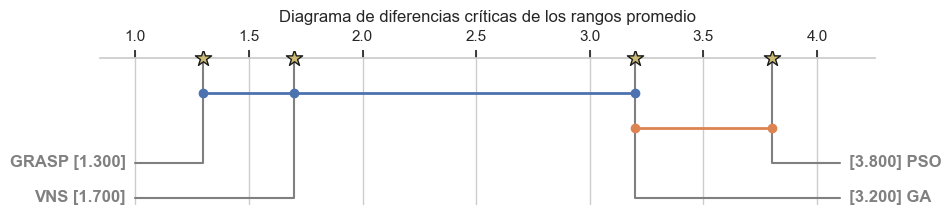

In [14]:
print("\n--- 8. Comparación de Múltiples Algoritmos (K > 2) ---")
alpha_comparacion = 0.05 # Nivel de significancia

if not results_df.empty and len(ALGORITHM_NAMES) > 2:
    # --- Escenario 1: Muestras Independientes en UNA instancia (Kruskal-Wallis) ---
    if results_df['instance'].nunique() > 0:
        target_instance_omnibus = results_df['instance'].unique()[0]
        print(f"\n  Escenario 1: Comparación en la instancia '{target_instance_omnibus}' (Usando Kruskal-Wallis)")

        # Preparar datos para Kruskal-Wallis
        kw_data = results_df[
            (results_df['instance'] == target_instance_omnibus) &
            (results_df['algorithm'].isin(ALGORITHM_NAMES))
        ]

        if not kw_data.empty and kw_data['algorithm'].nunique() > 2:
            try:
                # Realizar Kruskal-Wallis usando scipy.stats
                groups = [group for _, group in kw_data.groupby('algorithm')['fitness']]
                kw_stat, kw_p = stats.kruskal(*groups)
                print(f"    Test de Kruskal-Wallis: H = {kw_stat:.2f}, p-valor = {kw_p:.4f}")

                if kw_p <= alpha_comparacion:
                    print("      Hay diferencias significativas entre al menos dos algoritmos en esta instancia.")
                    print("      Realizando prueba post-hoc de Dunn (con corrección de Holm)...")

                    # Realizar prueba post-hoc de Dunn
                    dunn_results = sp.posthoc_dunn(kw_data, val_col='fitness', group_col='algorithm', p_adjust='holm')
                    print("    Resultados Post-Hoc de Dunn (p-valores ajustados con Holm):")
                    print(dunn_results)
                else:
                    print("      No hay diferencias significativas entre los algoritmos según Kruskal-Wallis en esta instancia.")
            except Exception as e_kw:
                print(f"    Error al ejecutar Kruskal-Wallis: {e_kw}")
        else:
            print(f"    No hay suficientes grupos de algoritmos (>2) en '{target_instance_omnibus}' para Kruskal-Wallis.")
    else:
        print("  No hay instancias para realizar la comparación del Escenario 1.")

    # --- Escenario 2: Muestras Pareadas a través de MÚLTIPLES instancias (Test de Friedman) ---
    if results_df['instance'].nunique() > 1:
        print(f"\n  Escenario 2: Comparación a través de {results_df['instance'].nunique()} instancias (Test de Friedman)")

        # Preparar datos para Friedman usando medianas por instancia
        friedman_data = results_df.groupby(['instance', 'algorithm'])['fitness'].median().unstack()
        friedman_data_cleaned = friedman_data.dropna()

        if not friedman_data_cleaned.empty and friedman_data_cleaned.shape[0] >= 2 and friedman_data_cleaned.shape[1] > 2:
            try:
                # Realizar test de Friedman usando scipy.stats
                friedman_stat, friedman_p = stats.friedmanchisquare(*[friedman_data_cleaned[col] for col in friedman_data_cleaned.columns])
                print(f"    Test de Friedman: Estadístico = {friedman_stat:.2f}, p-valor = {friedman_p:.4f}")

                # Calcular W de Kendall
                k = friedman_data_cleaned.shape[1]
                n = friedman_data_cleaned.shape[0]
                if k > 1 and n > 0:
                    kendall_w = friedman_stat / (n * (k - 1))
                    print(f"      W de Kendall: {kendall_w:.4f}")

                if friedman_p <= alpha_comparacion:
                    print("      Hay diferencias significativas entre al menos dos algoritmos según Friedman.")
                    print("      Realizando pruebas post-hoc de Nemenyi...")

                    # Realizar prueba post-hoc de Nemenyi
                    nemenyi_results = sp.posthoc_nemenyi_friedman(friedman_data_cleaned)
                    print("\n    Resultados Post-Hoc de Nemenyi (matriz de p-valores):")
                    print(nemenyi_results)

                    # Generar Diagrama de Diferencia Crítica
                    print("\n    Generando Diagrama de Diferencia Crítica (Nemenyi)...")
                    try:
                        # Calcular rangos promedio
                        avg_ranks = friedman_data_cleaned.rank(axis=1, method='average').mean(axis=0).sort_values()

                        # Crear el diagrama de diferencia crítica siguiendo el tutorial
                        plt.figure(figsize=(10, 2), dpi=100)
                        plt.title('Diagrama de diferencias críticas de los rangos promedio')
                        sp.critical_difference_diagram(
                            ranks=avg_ranks,
                            sig_matrix=nemenyi_results,
                            label_fmt_left='{label} [{rank:.3f}]  ',
                            label_fmt_right='  [{rank:.3f}] {label}',
                            text_h_margin=0.3,
                            label_props={'fontweight': 'bold'},
                            crossbar_props={'color': None, 'marker': 'o'},
                            marker_props={'marker': '*', 's': 150, 'color': 'y', 'edgecolor': 'k'},
                            elbow_props={'color': 'gray'}
                        )
                        plt.show()
                    except Exception as e_cd:
                        print(f"    Error al generar CD Diagram: {e_cd}")
                        # Fallback a gráfico de rangos promedio
                        plt.figure(figsize=(8, max(3, 0.5 * k)))
                        avg_ranks.plot(kind='barh', color='skyblue')
                        plt.title('Rangos promedio (Friedman significativo)')
                        plt.xlabel('Rango promedio (menor es mejor)')
                        plt.gca().invert_yaxis()
                        plt.tight_layout()
                        plt.show()
                else:
                    print("      No hay diferencias significativas entre los algoritmos según Friedman.")
                    # Mostrar rangos promedio
                    avg_ranks = friedman_data_cleaned.rank(axis=1, method='average').mean(axis=0).sort_values()
                    print("\n    Rangos Promedio de los Algoritmos:")
                    print(avg_ranks)
                    plt.figure(figsize=(8, max(3, 0.5 * k)))
                    avg_ranks.plot(kind='barh', color='skyblue')
                    plt.title('Rangos promedio de los algoritmos (Friedman no significativo)')
                    plt.xlabel('Rango promedio (menor es mejor)')
                    plt.gca().invert_yaxis()
                    plt.tight_layout()
                    plt.show()
            except Exception as e_friedman:
                print(f"    Error al ejecutar Test de Friedman: {e_friedman}")
        else:
            print("    No hay suficientes datos para el Test de Friedman.")
    else:
        print("\n  No hay múltiples instancias válidas para el Test de Friedman.")
else:
    print("Se necesitan al menos 3 algoritmos para comparaciones múltiples.")

En la primera instancia, la prueba de Kruskal-Wallis da $H = 25{,}19$ y un valor $p$ que se imprime como 0,0000, es decir, menor que 0,00005, así que al menos dos algoritmos difieren. La prueba de Dunn con la corrección de Holm separa dos grupos. GRASP y VNS no difieren entre sí ($p = 1$), y cada uno difiere del algoritmo genético ($p = 0{,}028$) y del PSO ($p = 0{,}0002$). El algoritmo genético y el PSO no difieren entre sí ($p = 0{,}31$), a pesar de que la prueba de Mann-Whitney de la sección anterior sí los distinguía; la diferencia está en que aquí la corrección de Holm ajusta seis comparaciones y en que la prueba de Dunn usa los rangos de los cuatro algoritmos a la vez.

A través de las instancias, la prueba de Friedman da $\chi^2_F = 13{,}60$ con $p = 0{,}0035$, y la $W$ de Kendall vale 0,91, lo que indica que las cinco instancias ordenan los algoritmos casi de la misma manera. Los rangos promedio son 1,3 para GRASP, 1,7 para VNS, 3,2 para el algoritmo genético y 3,8 para el PSO. La prueba de Nemenyi, en cambio, solo encuentra diferencias significativas entre GRASP y el PSO ($p = 0{,}012$) y entre VNS y el PSO ($p = 0{,}0496$). El diagrama de diferencias críticas lo resume con dos barras, una que une GRASP, VNS y el algoritmo genético y otra que une el algoritmo genético y el PSO. Con cinco instancias, la evidencia alcanza para afirmar que GRASP y VNS superan al PSO, pero no para separarlos del algoritmo genético, aunque dentro de la primera instancia esa diferencia sí aparezca.

Que una diferencia sea significativa tampoco dice que sea relevante en la práctica. Para eso están los tamaños de efecto, y también la pregunta de cuánto vale, en el problema real, acortar un recorrido en unas pocas unidades.

## Para ampliar el experimento

El experimento de este capítulo es deliberadamente pequeño. Para sacar conclusiones con más respaldo habría que ajustar primero los hiperparámetros de cada metaheurística, por ejemplo con Optuna como en el capítulo 15, para no comparar un algoritmo bien calibrado con otro mal calibrado; usar más instancias, más grandes y más variadas, que es lo que da potencia a las pruebas de Wilcoxon y de Friedman; aumentar el número de corridas por instancia, y usar versiones más elaboradas de PSO, GRASP y VNS.